# Notebook 05 — Neural Network Classification with TensorFlow

**Level:** Beginner to Intermediate  
**Track:** Deep Learning with TensorFlow  
**Main tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib, and scikit-learn  
**Problem type:** Binary classification

This notebook develops a complete binary-classification workflow. You will move from probability outputs and binary cross-entropy to model training, threshold selection, confusion-matrix analysis, and threshold-independent evaluation.

> **Important:** The dataset in this notebook is synthetic and is used only for learning. The model is not a diagnostic or clinical tool.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain binary classification and represent labels using 0 and 1.
2. Interpret a sigmoid output as a model-estimated probability.
3. Explain logits, probabilities, and decision thresholds.
4. Derive and calculate binary cross-entropy loss.
5. Build and train a binary MLP with the Keras API.
6. Interpret a confusion matrix and calculate common classification metrics.
7. Explain why accuracy can be misleading for imbalanced datasets.
8. Generate ROC and precision–recall curves from probability scores.
9. Select a decision threshold using validation data without tuning on the test set.
10. Compare a neural network with simple baseline classifiers.

## Notebook Roadmap

| Section | Topic |
|---|---|
| 1 | Binary classification and probability outputs |
| 2 | Sigmoid activation, logits, and decision thresholds |
| 3 | Binary cross-entropy loss |
| 4 | Confusion matrix and classification metrics |
| 5 | Create and explore an imbalanced synthetic dataset |
| 6 | Stratified splitting and feature scaling |
| 7 | Baseline classifiers |
| 8 | Build and compile a Keras MLP |
| 9 | Train the model and inspect learning curves |
| 10 | Evaluate probabilities and tune a threshold |
| 11 | ROC and precision–recall analysis |
| 12 | Class imbalance, error analysis, and common pitfalls |
| 13 | Exercises and further reading |

Run the notebook from top to bottom. The test set is reserved for final evaluation and must not be used to choose model settings or a decision threshold.

## 1. Binary Classification as a Supervised Learning Problem

### 1.1 What Is Binary Classification?

Binary classification is a supervised-learning task in which each observation belongs to one of two classes. We commonly encode the negative class as `0` and the positive class as `1`.

Examples include:

- Spam versus non-spam email.
- A transaction flagged as fraudulent versus not flagged.
- A machine component classified as faulty versus non-faulty.
- A sample assigned to one of two predefined experimental groups.

The phrase **positive class** does not mean that the class is desirable. It simply identifies the event that the model is designed to detect.

### 1.2 Features, Labels, Scores, and Predictions

For observation $i$, let the input feature vector be $\mathbf{x}_i$ and its true binary label be $y_i$:

$$
y_i \in \{0,1\}
$$

A neural network first computes a real-valued score, often called a **logit**, and may transform that score into a probability. A decision rule then converts the probability into a class prediction.

These are three different objects:

| Object | Meaning | Typical range |
|---|---|---|
| Logit | Unbounded model score | $(-\infty, +\infty)$ |
| Probability estimate | Estimated probability of class 1 | $[0,1]$ |
| Class prediction | Assigned class label | $\{0,1\}$ |

A probability estimate is not automatically a calibrated or clinically meaningful probability. Calibration must be assessed separately when probability interpretation matters.

### 1.3 The Classification Function

A binary classifier can be written as:

$$
\hat{p}_i = f_{\theta}(\mathbf{x}_i)
$$

where $\hat{p}_i$ is the estimated probability that observation $i$ belongs to the positive class and $\theta$ represents the trainable parameters.

A threshold $t$ converts this probability into a class prediction:

$$
\hat{y}_i =
\begin{cases}
1 & \text{if } \hat{p}_i \geq t \\
0 & \text{if } \hat{p}_i < t
\end{cases}
$$

The conventional default is often $t=0.5$, but it is not universally optimal. The appropriate threshold depends on the intended use, error costs, and operational constraints.

## 2. Sigmoid Activation, Logits, and Decision Thresholds

### 2.1 The Sigmoid Function

A common output activation for a single-output binary classifier is the sigmoid function:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

It maps any real-valued logit $z$ to a value strictly between 0 and 1. The function is monotonic: larger logits produce larger estimated probabilities.

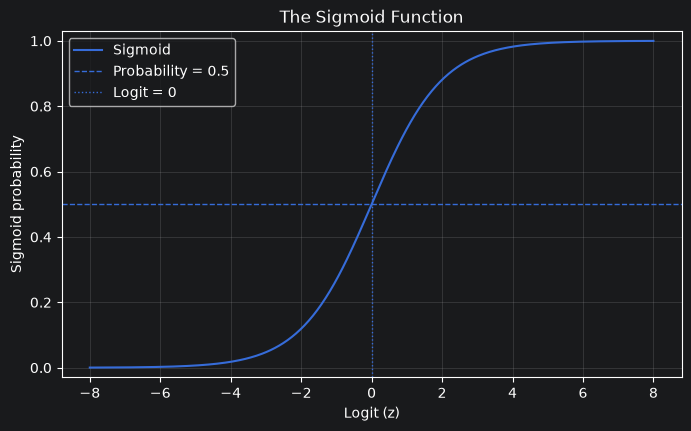

In [1]:
import numpy as np
import matplotlib.pyplot as plt

logits_for_plot = np.linspace(-8, 8, 400)
sigmoid_values = 1.0 / (1.0 + np.exp(-logits_for_plot))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(logits_for_plot, sigmoid_values, label="Sigmoid")
ax.axhline(0.5, linestyle="--", linewidth=1, label="Probability = 0.5")
ax.axvline(0.0, linestyle=":", linewidth=1, label="Logit = 0")
ax.set(title="The Sigmoid Function", xlabel="Logit (z)", ylabel="Sigmoid probability")
ax.set_ylim(-0.03, 1.03)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 2.2 From Logit to Probability

The inverse relationship is the logit, or log-odds, transformation:

$$
z = \log\left(\frac{p}{1-p}\right)
$$

For a sigmoid output, a logit of zero corresponds to a probability of $0.5$. A positive logit corresponds to a probability above $0.5$, while a negative logit corresponds to a probability below $0.5$.

The sigmoid transformation does not, by itself, guarantee good calibration. It only constrains the output to the probability interval.

In [2]:
example_logits = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])
example_probabilities = 1.0 / (1.0 + np.exp(-example_logits))

for logit, probability in zip(example_logits, example_probabilities):
    print(f"logit={logit:>5.1f}  probability={probability:.3f}")

logit= -3.0  probability=0.047
logit= -1.0  probability=0.269
logit=  0.0  probability=0.500
logit=  1.0  probability=0.731
logit=  3.0  probability=0.953


### 2.3 Decision Thresholds

The threshold is a decision-policy parameter, not a trainable neural-network weight. Reducing the threshold generally labels more observations as positive. This often increases recall while potentially reducing precision. Increasing it generally has the opposite effect.

A threshold of $0.5$ is a useful starting point, not a universal rule. In a real application, threshold selection should reflect the costs of false positives and false negatives and should be performed using validation data or an appropriately designed validation procedure.

In [3]:
example_probabilities = np.array([0.08, 0.31, 0.48, 0.52, 0.73, 0.91])
thresholds_to_compare = [0.30, 0.50, 0.70]

for threshold in thresholds_to_compare:
    predicted_labels = (example_probabilities >= threshold).astype(int)
    print(f"threshold={threshold:.2f} -> predictions={predicted_labels.tolist()}")

threshold=0.30 -> predictions=[0, 1, 1, 1, 1, 1]
threshold=0.50 -> predictions=[0, 0, 0, 1, 1, 1]
threshold=0.70 -> predictions=[0, 0, 0, 0, 1, 1]


## 3. Binary Cross-Entropy Loss

### 3.1 Why Use Binary Cross-Entropy?

The model should be penalized when it assigns a low probability to the true class. Binary cross-entropy (BCE), also called logarithmic loss or log loss, measures the discrepancy between a binary target and a predicted probability.

For one observation:

$$
\mathcal{L}_{\mathrm{BCE}}(y,p) = -\left[y\log(p) + (1-y)\log(1-p)\right]
$$

For $N$ observations, the mean loss is:

$$
J = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(\hat{p}_i) + (1-y_i)\log(1-\hat{p}_i)\right]
$$

where $y_i \in \{0,1\}$ and $\hat{p}_i$ is the estimated probability of class 1.

### 3.2 Interpreting the Loss

- If the true label is 1, the loss is $-\log(p)$ and becomes small when $p$ is close to 1.
- If the true label is 0, the loss is $-\log(1-p)$ and becomes small when $p$ is close to 0.
- Confident but incorrect predictions receive a large penalty.

The logarithm makes the loss sensitive to confident mistakes. In numerical implementations, clipping or stable logit-based formulations avoid taking the logarithm of exactly zero.

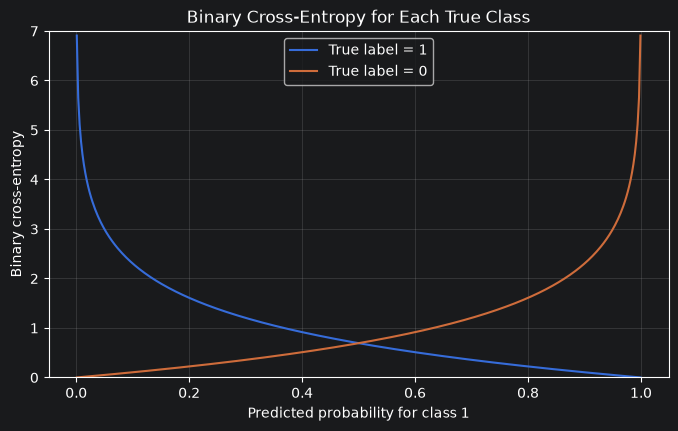

In [4]:
probability_grid = np.linspace(0.001, 0.999, 400)
loss_if_positive = -np.log(probability_grid)
loss_if_negative = -np.log(1.0 - probability_grid)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(probability_grid, loss_if_positive, label="True label = 1")
ax.plot(probability_grid, loss_if_negative, label="True label = 0")
ax.set(title="Binary Cross-Entropy for Each True Class", xlabel="Predicted probability for class 1", ylabel="Binary cross-entropy")
ax.set_ylim(0, 7)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [5]:
def binary_cross_entropy_numpy(y_true, y_probability, epsilon=1e-7):
    """Compute mean binary cross-entropy with probability clipping."""
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_probability = np.asarray(y_probability, dtype=float).reshape(-1)
    if y_true.shape != y_probability.shape:
        raise ValueError("y_true and y_probability must have the same shape.")
    if not np.isin(y_true, [0.0, 1.0]).all():
        raise ValueError("Labels must contain only 0 and 1.")
    y_probability = np.clip(y_probability, epsilon, 1.0 - epsilon)
    losses = -(y_true * np.log(y_probability) + (1.0 - y_true) * np.log(1.0 - y_probability))
    return float(np.mean(losses))

sample_y_true = np.array([1, 0, 1, 0])
well_ranked_probabilities = np.array([0.90, 0.10, 0.80, 0.20])
poorly_ranked_probabilities = np.array([0.20, 0.80, 0.40, 0.70])

print("Well-ranked probabilities:", binary_cross_entropy_numpy(sample_y_true, well_ranked_probabilities))
print("Poorly ranked probabilities:", binary_cross_entropy_numpy(sample_y_true, poorly_ranked_probabilities))

Well-ranked probabilities: 0.164252033486018
Poorly ranked probabilities: 1.334784840267073


### 3.3 Probabilities Versus Logits in Keras

Keras supports two consistent output/loss configurations:

| Model output | Final layer | Loss setting |
|---|---|---|
| Probability | `Dense(1, activation="sigmoid")` | `BinaryCrossentropy(from_logits=False)` |
| Logit | `Dense(1)` with no sigmoid | `BinaryCrossentropy(from_logits=True)` |

Do not apply sigmoid twice. If the model already outputs probabilities, use `from_logits=False`. If the model outputs raw logits, use `from_logits=True` and apply sigmoid only when probabilities are needed for interpretation or thresholding.

For this notebook, the main model will output probabilities using a sigmoid activation.

In [6]:
# Illustrative Keras configurations (the main model is built later).
# Probability output:
# output = keras.layers.Dense(1, activation="sigmoid")(hidden)
# loss = keras.losses.BinaryCrossentropy(from_logits=False)

# Logit output (alternative):
# output = keras.layers.Dense(1)(hidden)
# loss = keras.losses.BinaryCrossentropy(from_logits=True)

## 4. Confusion Matrix and Classification Metrics

### 4.1 The Four Outcomes

A confusion matrix compares predicted class labels with true labels:

| | Predicted negative | Predicted positive |
|---|---:|---:|
| **Actual negative** | True Negative (TN) | False Positive (FP) |
| **Actual positive** | False Negative (FN) | True Positive (TP) |

- **True Positive:** a positive observation correctly identified.
- **True Negative:** a negative observation correctly identified.
- **False Positive:** a negative observation incorrectly classified as positive.
- **False Negative:** a positive observation incorrectly classified as negative.

In [7]:
# A small worked example: rows are true labels and columns are predicted labels.
y_true_demo = np.array([0, 0, 0, 0, 1, 1, 1, 1])
y_pred_demo = np.array([0, 0, 1, 0, 0, 1, 1, 1])

from sklearn.metrics import confusion_matrix

cm_demo = confusion_matrix(y_true_demo, y_pred_demo, labels=[0, 1])
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm_demo)

Confusion matrix [[TN, FP], [FN, TP]]:
[[3 1]
 [1 3]]


### 4.2 Core Metrics

**Accuracy** measures the fraction of all predictions that are correct:

$$
\mathrm{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN}
$$

**Precision** measures the fraction of predicted positives that are truly positive:

$$
\mathrm{Precision} = \frac{TP}{TP+FP}
$$

**Recall**, also called sensitivity or true-positive rate, measures the fraction of actual positives that are identified:

$$
\mathrm{Recall} = \frac{TP}{TP+FN}
$$

**Specificity**, also called true-negative rate, measures the fraction of actual negatives that are correctly identified:

$$
\mathrm{Specificity} = \frac{TN}{TN+FP}
$$

**F1-score** is the harmonic mean of precision and recall:

$$
F_1 = 2\cdot\frac{\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}
$$

When a denominator is zero, the corresponding metric is mathematically undefined. Software libraries provide explicit conventions for this case; here we use `zero_division=0` for deterministic reporting.

### 4.3 Calculate Metrics for the Worked Example

The following code computes these metrics using scikit-learn. The positive label is explicitly set to `1`.

In [8]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

def classification_metrics_at_threshold(y_true, y_probability, threshold=0.5):
    """Return threshold-dependent binary metrics and confusion counts."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    y_probability = np.asarray(y_probability).reshape(-1)
    y_pred = (y_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

# Convert the worked-example labels into scores that reproduce the same decisions at 0.5.
y_probability_demo = np.array([0.10, 0.20, 0.80, 0.10, 0.40, 0.90, 0.75, 0.95])
metrics_demo = classification_metrics_at_threshold(y_true_demo, y_probability_demo, threshold=0.5)
for metric_name, metric_value in metrics_demo.items():
    print(f"{metric_name:>18}: {metric_value}")

         threshold: 0.5
          accuracy: 0.75
 balanced_accuracy: 0.75
         precision: 0.75
            recall: 0.75
       specificity: 0.75
                f1: 0.75
                tn: 3
                fp: 1
                fn: 1
                tp: 3


### 4.4 Why Accuracy Can Be Misleading

Imagine a dataset in which 95% of observations are negative and 5% are positive. A classifier that predicts every observation as negative achieves 95% accuracy but detects none of the positive cases.

For imbalanced datasets, report class prevalence and metrics such as precision, recall, specificity, F1-score, balanced accuracy, and PR-AUC alongside accuracy. No single metric fully describes model performance.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

imbalance_y = np.array([0] * 95 + [1] * 5)
all_negative_predictions = np.zeros_like(imbalance_y)
print(classification_report(imbalance_y, all_negative_predictions, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.950     1.000     0.974        95
           1      0.000     0.000     0.000         5

    accuracy                          0.950       100
   macro avg      0.475     0.500     0.487       100
weighted avg      0.902     0.950     0.926       100



## 5. Create and Explore a Synthetic Binary Dataset

### 5.1 Why Synthetic Data?

Synthetic data make the exercise reproducible and remove the need to download a dataset. We can control class prevalence, feature count, and class overlap. This dataset is designed to demonstrate model development and evaluation; it does not represent a real biological or medical population.

We use `make_classification` to generate ten numerical features and an imbalanced binary target. The positive class is less frequent than the negative class.

In [10]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

RANDOM_SEED = 42
N_SAMPLES = 2_400
N_FEATURES = 10

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

X_array, y = make_classification(
    n_samples=N_SAMPLES,
    n_features=N_FEATURES,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    weights=[0.82, 0.18],
    class_sep=1.0,
    flip_y=0.02,
    random_state=RANDOM_SEED,
)

feature_names = [f"feature_{i+1}" for i in range(N_FEATURES)]
X = pd.DataFrame(X_array, columns=feature_names)
y = np.asarray(y, dtype=np.int32)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
print("Positive class prevalence:", f"{y.mean():.3f}")

Feature matrix shape: (2400, 10)
Target shape: (2400,)
Class counts: {np.int32(0): np.int64(1950), np.int32(1): np.int64(450)}
Positive class prevalence: 0.188


In [11]:
# Inspect the first rows and basic feature statistics.
display(X.head())
display(X.describe().T.round(3))

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
0,-2.792051,-0.082331,-1.966891,-0.701306,-0.034257,-10.182956,-0.305008,-3.540843,-4.164118,-3.394017
1,-1.743335,-0.755975,-1.332450,0.630067,0.973337,0.566165,-1.398320,0.553905,-2.353296,1.423819
2,-1.537166,-2.566119,-0.508194,-1.576908,-0.149313,-3.757563,-3.939670,-2.742180,-3.336121,-1.767044
3,0.676284,0.070697,-2.068628,-2.082282,-0.720163,-1.982962,-1.030641,-0.602194,-1.911550,1.587484
4,0.507308,0.440820,-2.281975,-1.051563,-0.722597,-2.437134,0.243851,1.015876,0.849612,-0.813817


,count,mean,std,min,25%,50%,75%,max
feature_1,2400.0,-0.621,1.651,-6.735,-1.710,-0.708,0.436,5.233
feature_2,2400.0,0.038,0.997,-3.330,-0.633,0.029,0.713,4.479
feature_3,2400.0,-0.878,1.783,-7.058,-2.045,-0.894,0.327,5.205
feature_4,2400.0,0.171,1.745,-4.484,-1.127,-0.033,1.370,6.051
feature_5,2400.0,-0.001,1.013,-3.635,-0.689,0.010,0.699,3.140
feature_6,2400.0,-0.395,4.285,-14.862,-3.094,0.255,2.687,11.687
feature_7,2400.0,-0.961,1.182,-4.668,-1.769,-0.963,-0.187,3.031
feature_8,2400.0,-0.018,1.765,-6.627,-1.227,0.123,1.317,5.787
feature_9,2400.0,-0.967,2.053,-6.974,-2.356,-1.093,0.219,8.525
feature_10,2400.0,-0.020,1.708,-5.895,-1.124,0.111,1.201,5.313


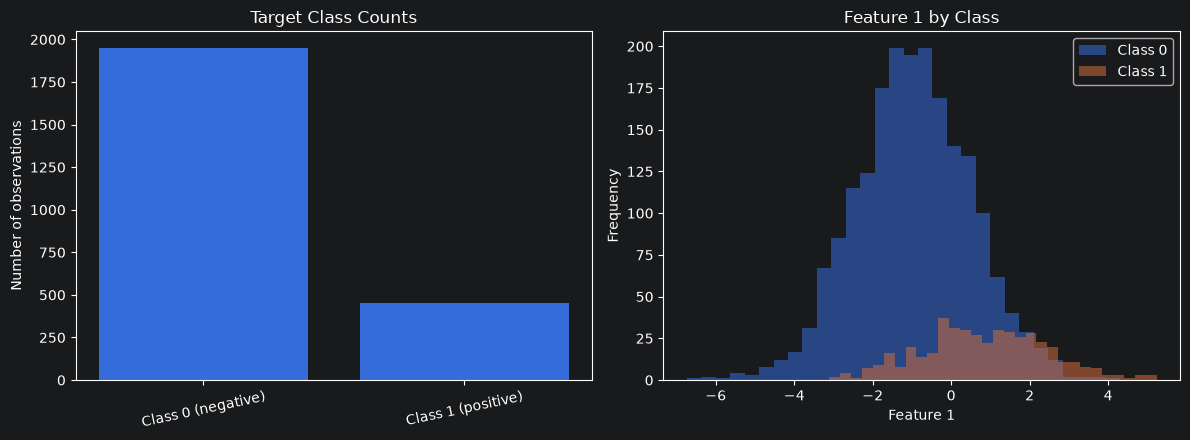

In [12]:
class_counts = pd.Series(y).value_counts().sort_index()
class_labels = ["Class 0 (negative)", "Class 1 (positive)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(class_labels, [class_counts.get(0, 0), class_counts.get(1, 0)])
axes[0].set(title="Target Class Counts", ylabel="Number of observations")
axes[0].tick_params(axis="x", rotation=12)

for label, color in [(0, "C0"), (1, "C1")]:
    axes[1].hist(X.loc[y == label, "feature_1"], bins=30, alpha=0.55, label=f"Class {label}", color=color)
axes[1].set(title="Feature 1 by Class", xlabel="Feature 1", ylabel="Frequency")
axes[1].legend()
plt.tight_layout()
plt.show()

### 5.2 Understand the Positive Class

In this notebook, label `1` is the positive class. The class distribution matters because a classifier can obtain high accuracy by favoring the majority class. We will therefore evaluate more than accuracy.

## 6. Stratified Splitting and Feature Scaling

### 6.1 Train, Validation, and Test Sets

We use three data partitions:

- **Training set:** used to fit model parameters.
- **Validation set:** used to compare settings and select the decision threshold.
- **Test set:** kept separate until the final evaluation.

A stratified split preserves approximately the same class proportions in each partition. We use a 70% / 15% / 15% split.

In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_SEED,
)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n_samples": [len(y_train), len(y_val), len(y_test)],
    "positive_count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "positive_prevalence": [y_train.mean(), y_val.mean(), y_test.mean()],
})
display(split_summary)

,split,n_samples,positive_count,positive_prevalence
0,train,1680,315,0.187500
1,validation,360,68,0.188889
2,test,360,67,0.186111


### 6.2 Fit Preprocessing on Training Data Only

Feature scaling can improve neural-network optimization. However, the scaler must be fitted on the training data only. Fitting it on validation or test observations would leak information from those partitions into model development.

The transformation is:

$$
x_{\mathrm{scaled}} = \frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

The training-set mean and standard deviation are then reused unchanged for validation and test data.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)
print("Training feature means (first 5):", np.round(X_train_scaled.mean(axis=0)[:5], 3))
print("Training feature standard deviations (first 5):", np.round(X_train_scaled.std(axis=0)[:5], 3))

Scaled training shape: (1680, 10)
Scaled validation shape: (360, 10)
Scaled test shape: (360, 10)
Training feature means (first 5): [-0. -0. -0.  0. -0.]
Training feature standard deviations (first 5): [1. 1. 1. 1. 1.]


### 6.3 Check Shapes and Label Encoding

For a single-output binary classifier, a common Keras convention is a feature array with shape `(n_samples, n_features)` and labels with shape `(n_samples,)` or `(n_samples, 1)`. We will use one-dimensional integer labels and a one-unit model output.

In [15]:
assert X_train_scaled.ndim == 2
assert X_val_scaled.ndim == 2
assert X_test_scaled.ndim == 2
assert set(np.unique(y_train)).issubset({0, 1})
assert len(X_train_scaled) == len(y_train)
assert len(X_val_scaled) == len(y_val)
assert len(X_test_scaled) == len(y_test)

print("All shape and label checks passed.")

All shape and label checks passed.


## 7. Baseline Classifiers

### 7.1 Why Build Baselines?

A neural network should be compared with simpler models. A baseline provides context for interpreting whether the additional complexity is useful.

We will compare:

1. A majority-class dummy classifier.
2. Logistic regression with balanced class weights.
3. A neural network trained in the next section.

All preprocessing has already been fitted using training data only.

In [16]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_scaled, y_train)
dummy_val_probability = dummy_model.predict_proba(X_val_scaled)[:, 1]

dummy_val_metrics = classification_metrics_at_threshold(
    y_val, dummy_val_probability, threshold=0.5
)
print("Majority-class baseline — validation set:")
for name, value in dummy_val_metrics.items():
    print(f"{name:>18}: {value}")

Majority-class baseline — validation set:
         threshold: 0.5
          accuracy: 0.8111111111111111
 balanced_accuracy: 0.5
         precision: 0.0
            recall: 0.0
       specificity: 1.0
                f1: 0.0
                tn: 292
                fp: 0
                fn: 68
                tp: 0


In [17]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1_000,
    random_state=RANDOM_SEED,
)
logistic_model.fit(X_train_scaled, y_train)
logistic_val_probability = logistic_model.predict_proba(X_val_scaled)[:, 1]

logistic_val_metrics = classification_metrics_at_threshold(
    y_val, logistic_val_probability, threshold=0.5
)
print("Balanced logistic-regression baseline — validation set:")
for name, value in logistic_val_metrics.items():
    print(f"{name:>18}: {value}")

Balanced logistic-regression baseline — validation set:
         threshold: 0.5
          accuracy: 0.7916666666666666
 balanced_accuracy: 0.8264504431909749
         precision: 0.47244094488188976
            recall: 0.8823529411764706
       specificity: 0.7705479452054794
                f1: 0.6153846153846154
                tn: 225
                fp: 67
                fn: 8
                tp: 60


## 8. Build a Binary Classification MLP with Keras

### 8.1 Architecture

The network will contain:

- An input matching the number of features.
- Two fully connected hidden layers with ReLU activations.
- A single sigmoid output representing the estimated probability of class 1.

For a binary task, a single sigmoid output is a common design. A two-unit softmax output is another possible formulation, but it is not required here.

### 8.2 Keras Setup and Reproducibility

We use TensorFlow's Keras interface. The random seed is set through Keras utilities to improve repeatability, although exact determinism can still depend on the hardware and operations used.

In [18]:
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(RANDOM_SEED)
print("TensorFlow version:", tf.__version__)
print("Keras version:", getattr(keras, "__version__", "bundled with TensorFlow"))

TensorFlow version: 2.21.0
Keras version: 3.15.1


### 8.3 Account for Class Imbalance with Training-Set Weights

Class weights increase the contribution of under-represented classes to the training loss. They must be calculated from training labels only.

The balanced class-weight heuristic is:

$$
w_k = \frac{N}{K\,N_k}
$$

where $N$ is the number of training observations, $K$ is the number of classes, and $N_k$ is the number of training observations in class $k$.

Class weighting changes the optimization objective. It does not create new positive observations, and it does not guarantee calibrated probability estimates. Its impact should be evaluated using held-out data.

In [19]:
classes = np.unique(y_train)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)
class_weight = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, class_weights_array)
}
print("Training class weights:", class_weight)

Training class weights: {0: 0.6153846153846154, 1: 2.6666666666666665}


### 8.4 Define the Model

We use ReLU in the hidden layers and sigmoid in the output layer. The output shape is `(batch_size, 1)`.

In [20]:
model = keras.Sequential(
    [
        keras.layers.Input(shape=(X_train_scaled.shape[1],)),
        keras.layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
        keras.layers.Dense(32, activation="relu", kernel_initializer="he_normal"),
        keras.layers.Dense(1, activation="sigmoid"),
    ],
    name="binary_classification_mlp",
)

model.summary()

Model: "binary_classification_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

### 8.5 Compile the Model

We use binary cross-entropy with `from_logits=False` because the final layer already applies sigmoid and therefore returns probabilities.

Keras precision and recall metrics use a threshold to convert probabilities into labels. The metrics specified below use the conventional threshold of 0.5 during training. Later, we will calculate metrics again with a validation-selected threshold.

In [21]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.5),
        keras.metrics.Precision(name="precision", thresholds=0.5),
        keras.metrics.Recall(name="recall", thresholds=0.5),
        keras.metrics.AUC(name="roc_auc", curve="ROC"),
        keras.metrics.AUC(name="pr_auc", curve="PR"),
    ],
)

print("Model compiled successfully.")

Model compiled successfully.


## 9. Train the Model and Inspect Learning Curves

### 9.1 Early Stopping

Early stopping monitors validation loss and stops training when it no longer improves for a specified number of epochs. With `restore_best_weights=True`, the model parameters are restored from the epoch with the best monitored validation loss.

The validation set is used for monitoring and model selection. It is not a substitute for the final test set.

In [22]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=60,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/60
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.6685 - loss: 0.6701 - pr_auc: 0.4618 - precision: 0.3073 - recall: 0.6127 - roc_auc: 0.6980 - val_accuracy: 0.7889 - val_loss: 0.4594 - val_pr_auc: 0.7532 - val_precision: 0.4692 - val_recall: 0.8971 - val_roc_auc: 0.9170
Epoch 2/60
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7982 - loss: 0.4248 - pr_auc: 0.7485 - precision: 0.4786 - recall: 0.8540 - roc_auc: 0.8963 - val_accuracy: 0.8361 - val_loss: 0.3855 - val_pr_auc: 0.8234 - val_precision: 0.5398 - val_recall: 0.8971 - val_roc_auc: 0.9405
Epoch 3/60
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8286 - loss: 0.3835 - pr_auc: 0.8076 - precision: 0.5262 - recall: 0.8603 - roc_auc: 0.9154 - val_accuracy: 0.8444 - val_loss: 0.3454 - val_pr_auc: 0.8638 - val_precision: 0.5556 - val_recall: 0.8824 - val_roc_auc: 0.9494
Epoch 4/60
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8548 - loss: 0.3523 - pr_auc: 0.8434 - precision: 0.5751 - recall: 0.8635 - r

In [23]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

,accuracy,loss,pr_auc,precision,recall,roc_auc,val_accuracy,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc
55,0.972619,0.095100,0.980335,0.901493,0.958730,0.995265,0.95,0.150859,0.933417,0.878788,0.852941,0.960742
56,0.973810,0.093374,0.980687,0.904478,0.961905,0.995428,0.95,0.150708,0.934229,0.878788,0.852941,0.961170
57,0.973810,0.091830,0.981334,0.904478,0.961905,0.995621,0.95,0.150342,0.934269,0.878788,0.852941,0.961372
58,0.973214,0.090392,0.981677,0.904192,0.958730,0.995754,0.95,0.150590,0.933007,0.878788,0.852941,0.960490
59,0.975595,0.088292,0.982319,0.912651,0.961905,0.995997,0.95,0.149667,0.934448,0.878788,0.852941,0.961649


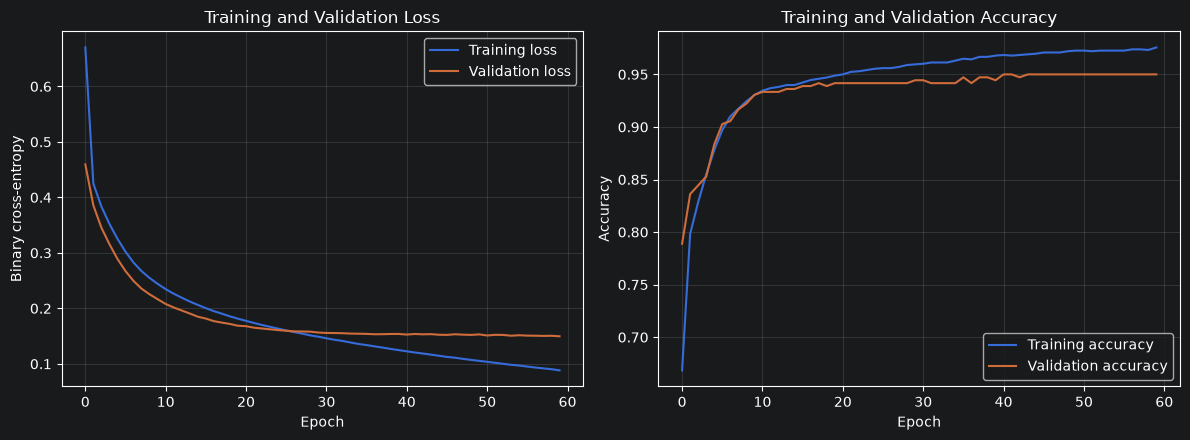

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set(title="Training and Validation Loss", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set(title="Training and Validation Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 9.2 Interpret the Learning Curves

Look for the relationship between training and validation curves:

- If both losses remain high, the model may be underfitting or the optimization setup may be inadequate.
- If training loss decreases while validation loss begins to increase, overfitting may be occurring.
- If both losses decrease and remain reasonably close, training may be progressing well.

A small gap does not prove generalization. The final test set remains necessary for an independent evaluation.

In [25]:
validation_loss_and_metrics = model.evaluate(X_val_scaled, y_val, verbose=0, return_dict=True)
print("Validation metrics at the compile-time metric settings:")
for metric_name, metric_value in validation_loss_and_metrics.items():
    print(f"{metric_name:>14}: {metric_value:.4f}")

print("The test set remains unused until the decision threshold has been selected.")

Validation metrics at the compile-time metric settings:
      accuracy: 0.9500
          loss: 0.1497
        pr_auc: 0.9344
     precision: 0.8788
        recall: 0.8529
       roc_auc: 0.9616
The test set remains unused until the decision threshold has been selected.


## 10. Probability Evaluation and Decision-Threshold Selection

### 10.1 Obtain Probability Scores

The model returns probabilities because its output layer uses sigmoid. Keep these continuous scores for ROC and precision–recall analysis; do not convert them to hard labels before calculating threshold-independent metrics.

In [26]:
val_probability = model.predict(X_val_scaled, verbose=0).ravel()

print("Probability range on validation data:", (float(val_probability.min()), float(val_probability.max())))

Probability range on validation data: (1.6112497291942418e-07, 1.0)


### 10.2 Evaluate the Default Threshold

Start with a threshold of 0.5. This gives a reference point, but do not assume it is the best threshold for the task.

In [27]:
validation_default_metrics = classification_metrics_at_threshold(
    y_val, val_probability, threshold=0.5
)
print("Validation metrics at threshold 0.5:")
for name, value in validation_default_metrics.items():
    print(f"{name:>18}: {value}")

Validation metrics at threshold 0.5:
         threshold: 0.5
          accuracy: 0.95
 balanced_accuracy: 0.9127719580983078
         precision: 0.8787878787878788
            recall: 0.8529411764705882
       specificity: 0.9726027397260274
                f1: 0.8656716417910447
                tn: 284
                fp: 8
                fn: 10
                tp: 58


### 10.3 Compare Thresholds on the Validation Set

We will evaluate a grid of candidate thresholds on validation probabilities. For this educational example, we select the threshold that maximizes validation F1-score.

This is one possible policy, not a universal rule. In a real application, threshold selection should reflect the intended operating point, error costs, capacity constraints, and any minimum sensitivity or specificity requirement.

In [28]:
threshold_grid = np.linspace(0.05, 0.95, 91)
threshold_rows = []

for threshold in threshold_grid:
    threshold_rows.append(
        classification_metrics_at_threshold(y_val, val_probability, threshold=threshold)
    )

threshold_results = pd.DataFrame(threshold_rows)
best_row_index = int(threshold_results["f1"].values.argmax())
selected_threshold = float(threshold_results.loc[best_row_index, "threshold"])

display(threshold_results.sort_values("f1", ascending=False).head(10).round(3))
print(f"Selected threshold based on validation F1: {selected_threshold:.3f}")

,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,tn,fp,fn,tp
74,0.79,0.964,0.910,0.982,0.824,0.997,0.896,291,1,12,56
76,0.81,0.964,0.910,0.982,0.824,0.997,0.896,291,1,12,56
75,0.80,0.964,0.910,0.982,0.824,0.997,0.896,291,1,12,56
70,0.75,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57
62,0.67,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57
65,0.70,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57
68,0.73,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57
60,0.65,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57
64,0.69,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57
61,0.66,0.961,0.914,0.950,0.838,0.990,0.891,289,3,11,57


Selected threshold based on validation F1: 0.790


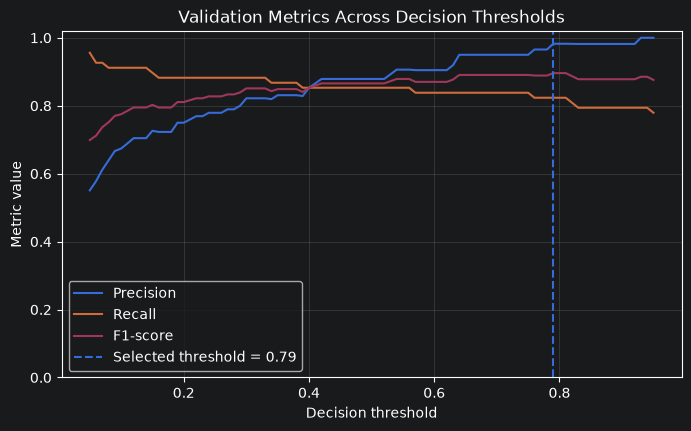

In [29]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_results["threshold"], threshold_results["precision"], label="Precision")
ax.plot(threshold_results["threshold"], threshold_results["recall"], label="Recall")
ax.plot(threshold_results["threshold"], threshold_results["f1"], label="F1-score")
ax.axvline(selected_threshold, linestyle="--", label=f"Selected threshold = {selected_threshold:.2f}")
ax.set(title="Validation Metrics Across Decision Thresholds", xlabel="Decision threshold", ylabel="Metric value")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 10.4 Freeze the Threshold and Evaluate the Test Set

The selected threshold is now fixed. We use it once on the test probabilities. Do not change the threshold after looking at test results; doing so would turn the test set into part of model development.

In [30]:
# The validation-selected threshold is now fixed. Only now do we obtain test predictions.
test_probability = model.predict(X_test_scaled, verbose=0).ravel()
test_loss_and_metrics = model.evaluate(X_test_scaled, y_test, verbose=0, return_dict=True)
print("Final Keras test metrics (compile-time metrics use threshold 0.5):")
for metric_name, metric_value in test_loss_and_metrics.items():
    print(f"{metric_name:>14}: {metric_value:.4f}")

test_default_metrics = classification_metrics_at_threshold(
    y_test, test_probability, threshold=0.5
)
test_selected_metrics = classification_metrics_at_threshold(
    y_test, test_probability, threshold=selected_threshold
)

comparison_thresholds = pd.DataFrame(
    [test_default_metrics, test_selected_metrics],
    index=["Default threshold (0.50)", f"Validation-selected threshold ({selected_threshold:.2f})"],
)
display(comparison_thresholds.round(3))

Final Keras test metrics (compile-time metrics use threshold 0.5):
      accuracy: 0.9417
          loss: 0.1964
        pr_auc: 0.8971
     precision: 0.8966
        recall: 0.7761
       roc_auc: 0.9453


,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,tn,fp,fn,tp
Default threshold (0.50),0.50,0.942,0.878,0.897,0.776,0.98,0.832,287,6,15,52
Validation-selected threshold (0.79),0.79,0.944,0.868,0.943,0.746,0.99,0.833,290,3,17,50


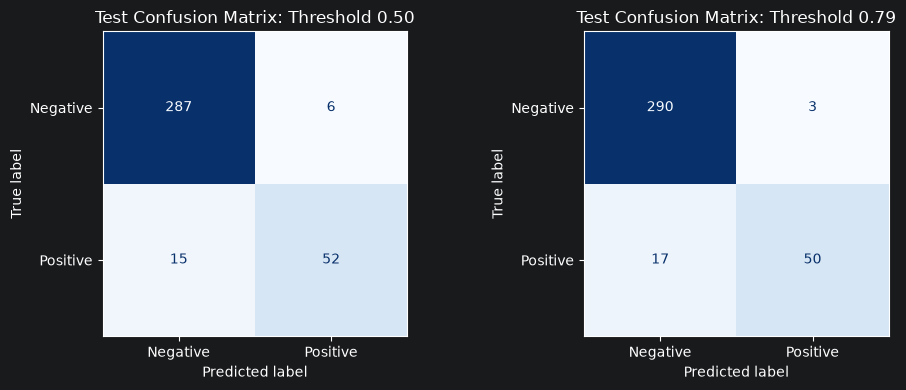

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, threshold, title in [
    (axes[0], 0.5, "Test Confusion Matrix: Threshold 0.50"),
    (axes[1], selected_threshold, f"Test Confusion Matrix: Threshold {selected_threshold:.2f}"),
]:
    y_test_pred = (test_probability >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_test_pred,
        labels=[0, 1],
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 11. Threshold-Independent Evaluation: ROC and Precision–Recall

### 11.1 ROC Curve

The receiver operating characteristic (ROC) curve plots the true-positive rate against the false-positive rate over a range of thresholds.

$$
\mathrm{TPR} = \frac{TP}{TP+FN}
\qquad
\mathrm{FPR} = \frac{FP}{FP+TN}
$$

ROC-AUC summarizes ranking performance across thresholds. It does not identify the best operating threshold and does not measure probability calibration.

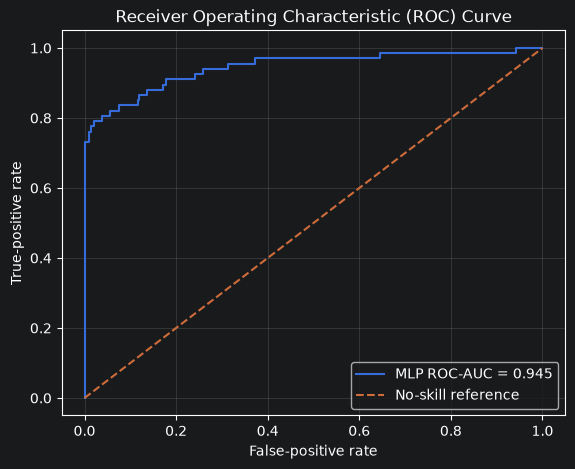

In [32]:
roc_fpr, roc_tpr, roc_thresholds = roc_curve(y_test, test_probability)
roc_auc_value = roc_auc_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(roc_fpr, roc_tpr, label=f"MLP ROC-AUC = {roc_auc_value:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="No-skill reference")
ax.set(title="Receiver Operating Characteristic (ROC) Curve", xlabel="False-positive rate", ylabel="True-positive rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.show()

### 11.2 Precision–Recall Curve

The precision–recall (PR) curve plots precision against recall as the threshold changes. It is particularly informative when the positive class is uncommon because it focuses on the quality of positive predictions and the fraction of positives found.

Average precision (AP) summarizes the precision–recall curve. It is not identical to trapezoidal area under the PR curve; scikit-learn's `average_precision_score` computes average precision using a weighted sum over recall increments.

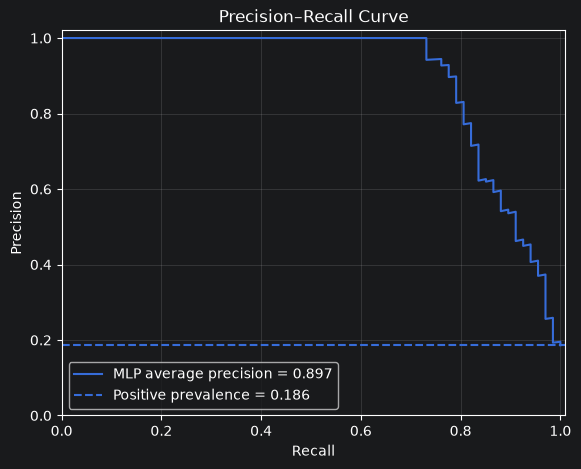

In [33]:
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test, test_probability)
average_precision = average_precision_score(y_test, test_probability)
test_prevalence = float(np.mean(y_test))

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(pr_recall, pr_precision, label=f"MLP average precision = {average_precision:.3f}")
ax.axhline(test_prevalence, linestyle="--", label=f"Positive prevalence = {test_prevalence:.3f}")
ax.set(title="Precision–Recall Curve", xlabel="Recall", ylabel="Precision")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")
ax.grid(alpha=0.25)
plt.show()

### 11.3 Compare the Neural Network with Baselines

ROC-AUC and average precision use continuous score values, so they assess ranking over thresholds rather than one selected threshold. The dummy classifier provides a simple reference. Logistic regression provides a useful linear baseline.

In [34]:
# Baseline test scores are generated only after model and threshold selection are complete.
dummy_test_probability = dummy_model.predict_proba(X_test_scaled)[:, 1]
logistic_test_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

model_comparison_rows = []

for model_name, probabilities in [
    ("Majority dummy", dummy_test_probability),
    ("Balanced logistic regression", logistic_test_probability),
    ("Neural network MLP", test_probability),
]:
    row = {
        "model": model_name,
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Average_Precision": average_precision_score(y_test, probabilities),
        "BCE": binary_cross_entropy_numpy(y_test, probabilities),
    }
    model_comparison_rows.append(row)

model_comparison = pd.DataFrame(model_comparison_rows).set_index("model")
display(model_comparison.round(4))

,ROC_AUC,Average_Precision,BCE
model,,,
Majority dummy,0.5000,0.1861,2.9998
Balanced logistic regression,0.8503,0.6455,0.4740
Neural network MLP,0.9445,0.8974,0.1964


## 12. Class Imbalance, Error Analysis, and Common Pitfalls

### 12.1 Common Approaches to Class Imbalance

Possible strategies include:

- **Class weighting:** increase the loss contribution of under-represented classes.
- **Sample weighting:** assign weights to individual observations.
- **Resampling:** oversample the minority class or undersample the majority class, using training data only.
- **Threshold selection:** choose an operating point based on validation data and task requirements.
- **Metric selection:** report metrics that reflect both classes and the intended error costs.

These methods are not interchangeable. Resampling and weighting alter the training procedure, while threshold selection changes the decision rule after probability scores are produced. Any imbalance strategy must be evaluated on data that retain the natural class distribution whenever that distribution represents the intended deployment setting.

### 12.2 Inspect False Positives and False Negatives

A confusion matrix summarizes counts but does not show which observations were misclassified. The following cell identifies false-positive and false-negative rows using the selected threshold.

In [35]:
y_test_pred_selected = (test_probability >= selected_threshold).astype(int)
false_positive_indices = np.flatnonzero((y_test == 0) & (y_test_pred_selected == 1))
false_negative_indices = np.flatnonzero((y_test == 1) & (y_test_pred_selected == 0))

print("False positives:", len(false_positive_indices))
print("False negatives:", len(false_negative_indices))

if len(false_positive_indices):
    print("\nFirst false-positive examples (test-set row indices):", false_positive_indices[:10].tolist())
if len(false_negative_indices):
    print("First false-negative examples (test-set row indices):", false_negative_indices[:10].tolist())

False positives: 3
False negatives: 17

First false-positive examples (test-set row indices): [109, 120, 145]
First false-negative examples (test-set row indices): [35, 47, 65, 82, 138, 154, 178, 179, 231, 267]


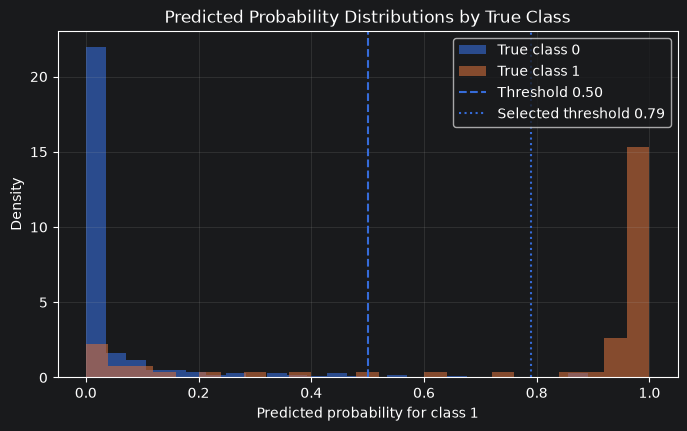

In [36]:
# Show probability distributions by true class to inspect overlap.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(test_probability[y_test == 0], bins=25, alpha=0.6, density=True, label="True class 0")
ax.hist(test_probability[y_test == 1], bins=25, alpha=0.6, density=True, label="True class 1")
ax.axvline(0.5, linestyle="--", label="Threshold 0.50")
ax.axvline(selected_threshold, linestyle=":", label=f"Selected threshold {selected_threshold:.2f}")
ax.set(title="Predicted Probability Distributions by True Class", xlabel="Predicted probability for class 1", ylabel="Density")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### 12.3 Common Mistakes to Avoid

1. **Using accuracy alone:** a majority-class classifier may appear strong on an imbalanced dataset.
2. **Confusing probabilities and labels:** ROC and PR curves require continuous scores, not thresholded labels.
3. **Using the wrong BCE setting:** match `from_logits` to the model output.
4. **Applying sigmoid twice:** use either a sigmoid output with `from_logits=False`, or logits with `from_logits=True`.
5. **Tuning on the test set:** choose thresholds and hyperparameters using validation data only.
6. **Data leakage:** fit scalers and resampling procedures using training data only.
7. **Ignoring the positive class definition:** document which label is treated as positive.
8. **Treating a default threshold as universal:** the operating point should reflect task-specific requirements.
9. **Interpreting AUC as calibration:** ranking quality and calibration are different properties.
10. **Over-interpreting synthetic results:** performance on generated data does not establish performance on real-world data.

## Key Takeaways

- A binary classifier can produce a probability estimate using a sigmoid output.
- Binary cross-entropy is a standard loss for binary labels.
- The model's probability output and the final class decision are different objects.
- A threshold changes the balance between precision and recall.
- Confusion-matrix metrics describe performance at a selected threshold.
- ROC-AUC and average precision evaluate scores across thresholds.
- Class imbalance requires careful metric selection and may motivate weighting or resampling.
- Threshold selection belongs on validation data; the test set is reserved for final evaluation.
- Baselines and error analysis are necessary parts of a credible model evaluation.

## Exercises

### Exercise 1 — Sigmoid and Logits

1. Calculate the sigmoid output for logits $z=-2, 0, 2$.
2. Explain why a logit of zero maps to probability 0.5.
3. Explain why sigmoid output alone does not guarantee calibration.

### Exercise 2 — Binary Cross-Entropy

For the true labels `[1, 0, 1, 0]` and probabilities `[0.8, 0.2, 0.4, 0.9]`:

1. Calculate the BCE for each observation.
2. Calculate the mean BCE.
3. Identify which observation contributes the largest loss and explain why.

### Exercise 3 — Confusion Matrix

Given $TP=42$, $TN=130$, $FP=18$, and $FN=10$:

1. Calculate accuracy, precision, recall, specificity, and F1-score.
2. Explain which metric changes most directly when false negatives become more common.
3. Explain why reporting accuracy alone would be incomplete.

### Exercise 4 — Threshold Selection

1. Run the threshold-search cell with F1 as the selection criterion.
2. Modify it to choose the highest-precision threshold among those with validation recall of at least 0.80.
3. Compare the resulting validation and test metrics. Do not select the threshold using test labels.

### Exercise 5 — Class Weighting

1. Train a second MLP without `class_weight`.
2. Compare its validation precision, recall, F1-score, ROC-AUC, and average precision with the weighted model.
3. Discuss why the best approach depends on the task and validation evidence.

### Exercise 6 — Model Architecture

Try one hidden layer, three hidden layers, and a smaller network. Keep the data split fixed and compare validation behavior. Avoid repeatedly selecting architectures based on the test set.

### Exercise 7 — Written Analysis

Write a short model evaluation report containing: positive-class definition, class prevalence, split strategy, preprocessing strategy, model architecture, loss function, threshold-selection rule, confusion matrix, ROC-AUC, average precision, limitations, and next steps.

## Further Reading and References

1. TensorFlow Core — [Basic classification: Classify images of clothing](https://www.tensorflow.org/tutorials/keras/classification/). The tutorial demonstrates the Keras classification workflow, model outputs, loss functions, and evaluation.
2. Keras — [Probabilistic losses](https://keras.io/api/losses/probabilistic_losses/). See `BinaryCrossentropy`, `from_logits`, and focal cross-entropy.
3. Keras — [Classification metrics](https://keras.io/api/metrics/classification_metrics/). See precision, recall, and AUC metrics.
4. Keras — [Accuracy metrics](https://keras.io/api/metrics/accuracy_metrics/). See `BinaryAccuracy` and its threshold behavior.
5. scikit-learn — [Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).
6. scikit-learn — [ROC curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html) and [ROC-AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).
7. scikit-learn — [Precision–recall curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html) and [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

**Next notebook:** Notebook 06 — Multiclass Classification and Model Evaluation.